# Quick PINN Tutorial with PyTorch 

## A Simple PINN Model

**Do without LLM**

In [4]:
import torch
import torch.nn as nn
import torch
import torch.nn as nn

class SimplePINN(nn.Module):
    def __init__(self):
        super(SimplePINN, self).__init__()
        # Takes (x, t) which is size (N, 2) as input and maps to u

        # Feel free to play around with the architecture!
        self.net = nn.Sequential(
            nn.Linear(2, 64), # Linear regression layer
            nn.Tanh(), # Non-linear activation function
            nn.Linear(64, 64),
            nn.Tanh(), # Use Tanh instead of ReLU for better performance in PINNs
            nn.Linear(64, 64),
            nn.Tanh(),
            nn.Linear(64, 1)
        )
        
    def forward(self, x, t):
        # Concatenate x and t into a single input tensor of shape (N, 2)
        X = torch.cat([x, t], dim=1)
        return self.net(X)

model = SimplePINN()
print(model)

SimplePINN(
  (net): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): Tanh()
    (4): Linear(in_features=64, out_features=64, bias=True)
    (5): Tanh()
    (6): Linear(in_features=64, out_features=1, bias=True)
  )
)


## Training Loop

Burger's equation is 

$$
\frac{\partial u}{\partial t} + u \frac{\partial u }{\partial x} = \nu \frac{\partial^2 u}{\partial x^2}
$$

If you reorder the equation:

$$
\frac{\partial u}{\partial t} + u \frac{\partial u }{\partial x} - \nu \frac{\partial^2 u}{\partial x^2} = 0
$$

Suppose $\hat{u}$ is the *model's* output. If our PINN were to actually work, we expect that 

$$
\frac{\partial \hat{u}}{\partial t} + \hat{u} \frac{\partial \hat{u} }{\partial x} - \nu \frac{\partial^2 \hat{u}}{\partial x^2} \rightarrow 0
$$

As our model gets more and more trained.

`compute_physics_loss()` literally just takes `u`, which is our $\hat{u}$ (again, the model's output), and see if that second equation goes to zero. 

For convenience purposes, we'll square the result of `pde_residual = u_t + u * u_x - nu * u_xx` to get a *magnitude*. If this thing tends to zero, then the square of that should also equal zero. So you'll need to return something like `pde_residual ** 2`. This is what `compute_physics_loss()` does. 

In [5]:
def compute_physics_loss(model, x, t, nu=0.01):
    # Ensure gradients can be computed with respect to x and t
    x.requires_grad_(True)
    t.requires_grad_(True)
    
    # Forward pass
    u = model(x, t)

    # torch.autograd() handles differentiation through AUTOMATIC DIFFERENTIATION!
    
    # First-order derivatives
    u_x = torch.autograd.grad(u, x, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_t = torch.autograd.grad(u, t, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    
    # Second-order derivative
    u_xx = torch.autograd.grad(u_x, x, grad_outputs=torch.ones_like(u_x), create_graph=True)[0]
    
    # Burgers' Equation residual: 
    # TODO: Implement the PDE residual for Burgers' equation 
    pde_residual = u_t + u * u_x - nu * u_xx
    return (pde_residual**2).mean()
    # We want this residual to be as close to 0 as possible
    raise NotImplementedError("Implement the PDE residual for Burgers' equation.")

Next, we have to calculate the initial condition loss and the boundary condition losses. In a nutshell, it's simply the sum of the MSE of the model prediction on the initial/boundary condition and the true value. 

In [6]:
def compute_data_loss(model, x_ic, t_ic, u_ic_target):
    # 1. Compute Data Losses (Initial Condition and Boundary Conditions)
    u_ic_pred = model(x_ic, t_ic)
    loss_ic = mse_loss(u_ic_pred, u_ic_target)
    
    u_bc_left_pred = model(x_bc_left, t_bc)
    u_bc_right_pred = model(x_bc_right, t_bc)
    loss_bc = mse_loss(u_bc_left_pred, u_bc_target) + mse_loss(u_bc_right_pred, u_bc_target)

    return loss_ic + loss_bc

Now that we have a way to quantify Physics loss, all we do is add a term (alongside an importance factor) $\lambda$. 

That is, the PINN loss (that we'll use) is:

$$
\lambda_1 (\text{MSE}) + \lambda_2 (\text{Physics Loss}) + \lambda_3 (\text{Initial Condition Loss})
$$

In [7]:
def PINNLoss(model, x, t, x_ic, t_ic, u_ic_target, nu=0.01,lambda1=0.1, lambda2=0.1, lambda3=0.1):
    # Forward pass
    #y_pred = model(x, t)
    
    # Compute the loss (Mean Squared Error)
    #model_loss = nn.MSELoss()(y_pred, y_true)
    phys_loss = compute_physics_loss(model, x, t, nu)
    data_loss = compute_data_loss(model, x_ic, t_ic, u_ic_target)

    # TODO: combine the MSE loss, data loss physics loss with a weighting factor
    #total_loss = lambda1 * model_loss + lambda2 * phys_loss + lambda3 * data_loss
    total_loss =  lambda2 * phys_loss + lambda3 * data_loss
    return total_loss
    raise NotImplementedError("Combine data_loss and phys_loss with a weighting factor.")

In [8]:
# Create training points for Initial Conditions (t = 0, x uniformly sampled between -1 and 1)
x_ic = torch.linspace(-1, 1, 100).view(-1, 1)
t_ic = torch.zeros_like(x_ic)
u_ic_target = -torch.sin(torch.pi * x_ic)

# Create training points for Boundary Conditions (x = -1 or x = 1, t uniformly sampled)
t_bc = torch.rand(100, 1)
x_bc_left = -torch.ones_like(t_bc)
x_bc_right = torch.ones_like(t_bc)
u_bc_target = torch.zeros_like(t_bc)

# Random interior collocation points for physics evaluation
x_collocation = (torch.rand(2000, 1) * 2) - 1  # Range [-1, 1]
t_collocation = torch.rand(2000, 1)             # Range [0, 1]

In [9]:
model = SimplePINN()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001) # An optimizer like gradient descesnt
mse_loss = nn.MSELoss()

for epoch in range(5000):
    optimizer.zero_grad()
    
    # Total Composite Loss
    total_loss = PINNLoss(model, x_collocation, t_collocation, x_ic, t_ic, u_ic_target, nu=0.01, lambda1=0.1, lambda2=0.1, lambda3=0.1)
    
    total_loss.backward()
    optimizer.step()
    
    if epoch % 500 == 0:
        print(f"Epoch {epoch} | Total Loss: {total_loss.item():.5f}")


Epoch 0 | Total Loss: 0.05231
Epoch 500 | Total Loss: 0.00635
Epoch 1000 | Total Loss: 0.00147
Epoch 1500 | Total Loss: 0.00078
Epoch 2000 | Total Loss: 0.00241
Epoch 2500 | Total Loss: 0.00044
Epoch 3000 | Total Loss: 0.00033
Epoch 3500 | Total Loss: 0.00027
Epoch 4000 | Total Loss: 0.00022
Epoch 4500 | Total Loss: 0.00018


# Your Task

**Do with/without LLM**

We'll use a very well known benchmark called the viscous Burger's benchmark. The initial conditions are:

$u(x,0) = −\sin(\pi x) \qquad \text{and} \qquad \nu = 0.01/\pi$

Train your PINN based on those initial conditions. Next, shrink $\nu$ from $0.001/\pi$ to $0.0001/\pi$. This will make the shock very very steep, which makes PINNs struggle!

In [10]:
model1 = SimplePINN()
optimizer = torch.optim.Adam(model1.parameters(), lr=0.001) # An optimizer like gradient descesnt
mse_loss = nn.MSELoss()

for epoch in range(5000):
    optimizer.zero_grad()
    
    # Total Composite Loss
    total_loss = PINNLoss(model1, x_collocation, t_collocation, x_ic, t_ic, u_ic_target, nu=0.01/torch.pi, lambda1=0.1, lambda2=0.1, lambda3=0.1)
    
    total_loss.backward()
    optimizer.step()
    
    if epoch % 500 == 0:
        print(f"Epoch {epoch} | Total Loss: {total_loss.item():.5f}")

Epoch 0 | Total Loss: 0.05146
Epoch 500 | Total Loss: 0.01071
Epoch 1000 | Total Loss: 0.00831
Epoch 1500 | Total Loss: 0.00679
Epoch 2000 | Total Loss: 0.00448
Epoch 2500 | Total Loss: 0.00198
Epoch 3000 | Total Loss: 0.00120
Epoch 3500 | Total Loss: 0.00087
Epoch 4000 | Total Loss: 0.00034
Epoch 4500 | Total Loss: 0.00027


In [11]:
model2 = SimplePINN()
optimizer = torch.optim.Adam(model2.parameters(), lr=0.001) # An optimizer like gradient descesnt
mse_loss = nn.MSELoss()

for epoch in range(5000):
    optimizer.zero_grad()
    
    # Total Composite Loss
    total_loss = PINNLoss(model2, x_collocation, t_collocation, x_ic, t_ic, u_ic_target, nu=0.001/torch.pi, lambda1=0.1, lambda2=0.1, lambda3=0.1)
    
    total_loss.backward()
    optimizer.step()
    
    if epoch % 500 == 0:
        print(f"Epoch {epoch} | Total Loss: {total_loss.item():.5f}")

Epoch 0 | Total Loss: 0.05234
Epoch 500 | Total Loss: 0.01081
Epoch 1000 | Total Loss: 0.00948
Epoch 1500 | Total Loss: 0.00878
Epoch 2000 | Total Loss: 0.00828
Epoch 2500 | Total Loss: 0.00798
Epoch 3000 | Total Loss: 0.00781
Epoch 3500 | Total Loss: 0.00769
Epoch 4000 | Total Loss: 0.00766
Epoch 4500 | Total Loss: 0.00753


In [12]:
model3 = SimplePINN()
optimizer = torch.optim.Adam(model3.parameters(), lr=0.001) # An optimizer like gradient descesnt
mse_loss = nn.MSELoss()

for epoch in range(5000):
    optimizer.zero_grad()
    
    # Total Composite Loss
    total_loss = PINNLoss(model3, x_collocation, t_collocation, x_ic, t_ic, u_ic_target, nu=0.0001/torch.pi, lambda1=0.1, lambda2=0.1, lambda3=0.1)
    
    total_loss.backward()
    optimizer.step()
    
    if epoch % 500 == 0:
        print(f"Epoch {epoch} | Total Loss: {total_loss.item():.5f}")

Epoch 0 | Total Loss: 0.04584
Epoch 500 | Total Loss: 0.01008
Epoch 1000 | Total Loss: 0.00871
Epoch 1500 | Total Loss: 0.00833
Epoch 2000 | Total Loss: 0.00791
Epoch 2500 | Total Loss: 0.00764
Epoch 3000 | Total Loss: 0.00740
Epoch 3500 | Total Loss: 0.00708
Epoch 4000 | Total Loss: 0.00693
Epoch 4500 | Total Loss: 0.00677


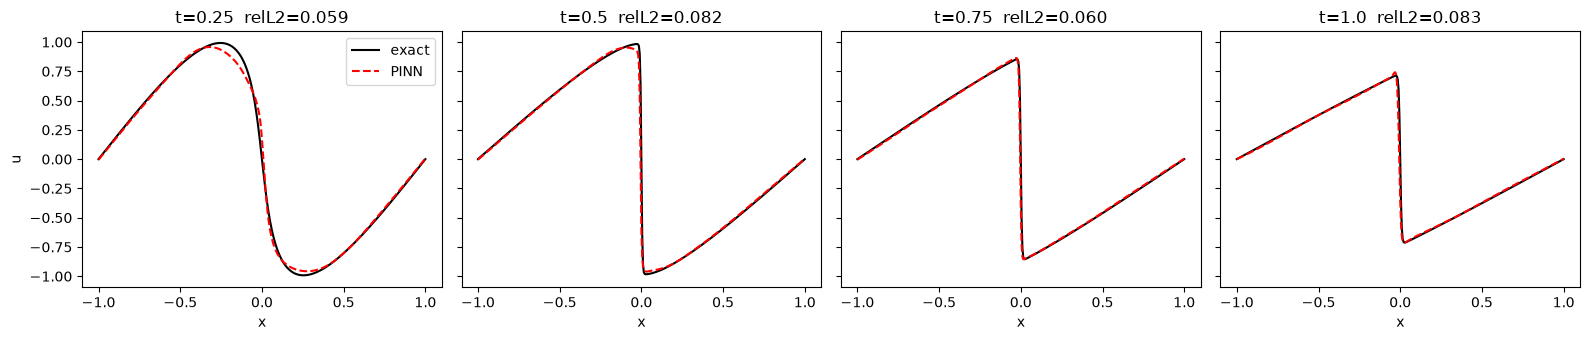

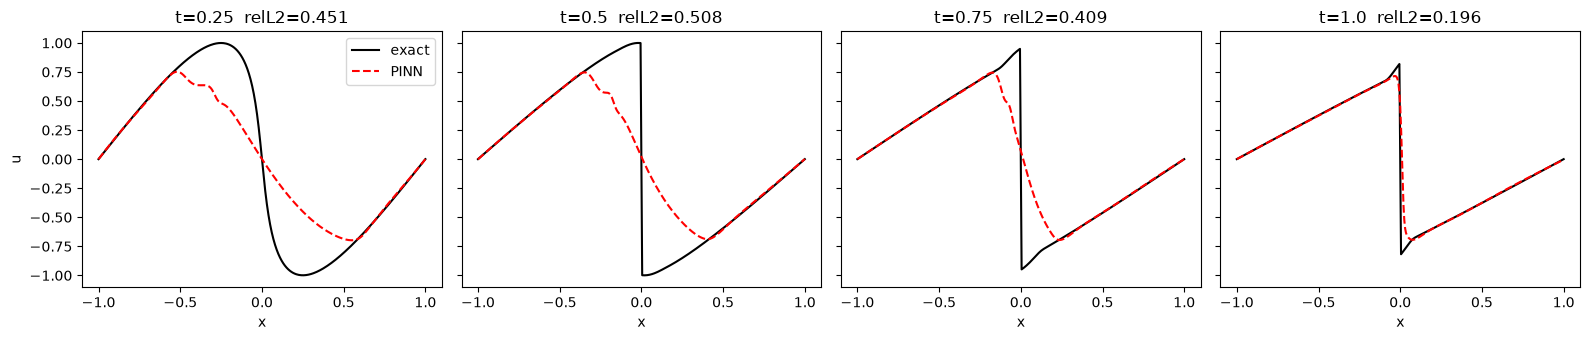

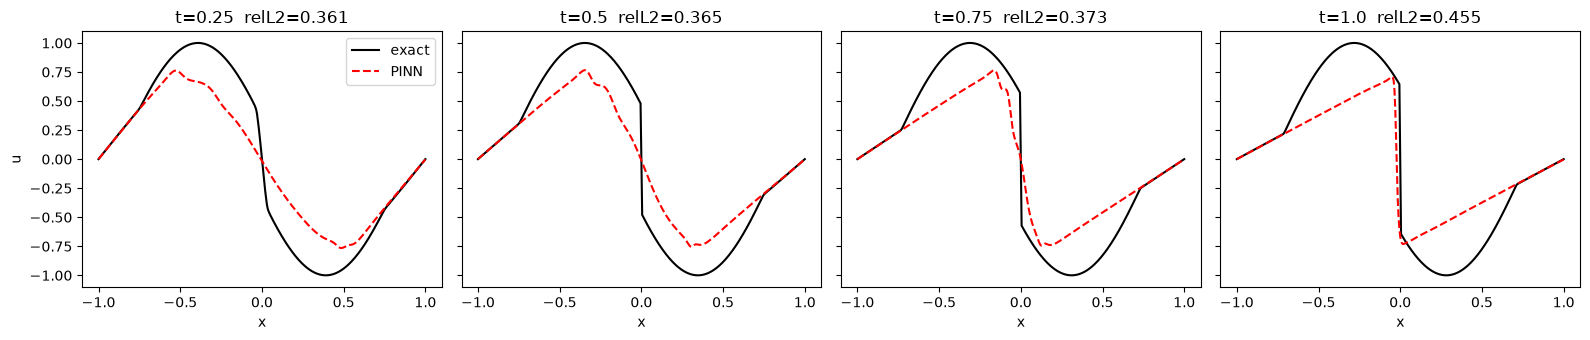

In [ ]:
import numpy as np
import torch
import matplotlib.pyplot as plt

def burgers_exact(x, t, nu, n=200):
    """Cole-Hopf solution for u(x,0) = -sin(pi x). x: 1D array, t: scalar > 0."""
    z, w = np.polynomial.hermite.hermgauss(n) # z: quadrature points (points for the evaluation of function), w: weights for Gauss-Hermite quadrature
    x = np.asarray(x)[:, None]
    y = x - 2*np.sqrt(nu*t)*z[None, :]
    logf = -np.cos(np.pi*y) / (2*np.pi*nu)
    logf -= logf.max(axis=1, keepdims=True)      # avoids overflow for small nu
    f = np.exp(logf)
    return (-np.sin(np.pi*y) * f * w).sum(axis=1) / (f * w).sum(axis=1)

def evaluate(model, nu, times=(0.25, 0.5, 0.75, 1.0)):
    xs = np.linspace(-1, 1, 401)
    x_t = torch.tensor(xs, dtype=torch.float32).view(-1, 1)
    fig, axes = plt.subplots(1, len(times), figsize=(4*len(times), 3.5), sharey=True)
    for ax, t in zip(axes, times):
        with torch.no_grad():
            u_pred = model(x_t, torch.full_like(x_t, t)).numpy().ravel()
        u_ex = burgers_exact(xs, t, nu)
        rel_l2 = np.linalg.norm(u_pred - u_ex) / np.linalg.norm(u_ex)
        ax.plot(xs, u_ex, 'k-', label='exact')
        ax.plot(xs, u_pred, 'r--', label='PINN')
        ax.set_title(f"t={t}  relL2={rel_l2:.3f}")
        ax.set_xlabel('x')
    axes[0].legend(); axes[0].set_ylabel('u')
    plt.tight_layout(); plt.show()

evaluate(model1, nu=0.01/np.pi)
evaluate(model2, nu=0.001/np.pi)
evaluate(model3, nu=0.0001/np.pi)

In [14]:
import numpy as np
import torch
import matplotlib.pyplot as plt

def rel_l2_vs_ref(model, nu, times=(0.25, 0.5, 0.75, 1.0)):
    """Mean relative L2 error against the reference over several times."""
    xs = np.linspace(-1, 1, 401)
    x_t = torch.tensor(xs, dtype=torch.float32).view(-1, 1)
    errs = []
    for t in times:
        with torch.no_grad():
            u_pred = model(x_t, torch.full_like(x_t, t)).numpy().ravel()
        u_ex = burgers_exact(xs, t, nu)
        errs.append(np.linalg.norm(u_pred - u_ex) / np.linalg.norm(u_ex))
    return float(np.mean(errs))

def train_with_tracking(model, nu, epochs=5000, every=50, lr=1e-3):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {"epoch": [], "loss": [], "ref_err": []}

    for epoch in range(epochs + 1):
        optimizer.zero_grad()
        total_loss = PINNLoss(model, x_collocation, t_collocation,
                              x_ic, t_ic, u_ic_target, nu=nu,
                              lambda1=0.1, lambda2=0.1, lambda3=0.1)
        total_loss.backward()
        optimizer.step()

        if epoch % every == 0:
            hist["epoch"].append(epoch)
            hist["loss"].append(total_loss.item())
            hist["ref_err"].append(rel_l2_vs_ref(model, nu))
    return hist

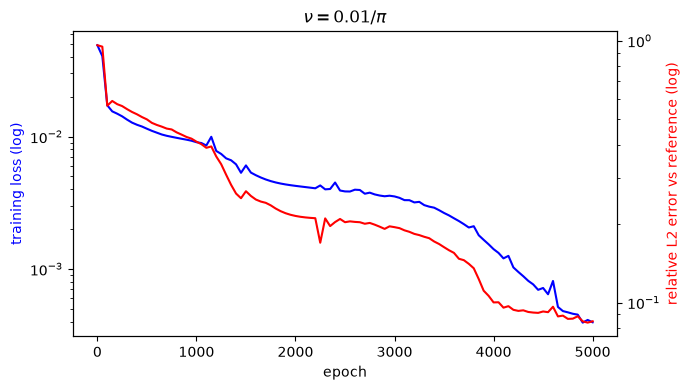

In [15]:
def plot_history(hist, title):
    fig, ax1 = plt.subplots(figsize=(7, 4))
    ax1.plot(hist["epoch"], hist["loss"], 'b-', label='training loss')
    ax1.set_xlabel('epoch')
    ax1.set_ylabel('training loss (log)', color='b')
    ax1.set_yscale('log')

    ax2 = ax1.twinx()
    ax2.plot(hist["epoch"], hist["ref_err"], 'r-', label='error vs reference')
    ax2.set_ylabel('relative L2 error vs reference (log)', color='r')
    ax2.set_yscale('log')

    ax1.set_title(title)
    fig.tight_layout()
    plt.show()

nu = 0.01/np.pi
model_a = SimplePINN()
hist_a = train_with_tracking(model_a, nu)
plot_history(hist_a, r"$\nu = 0.01/\pi$")

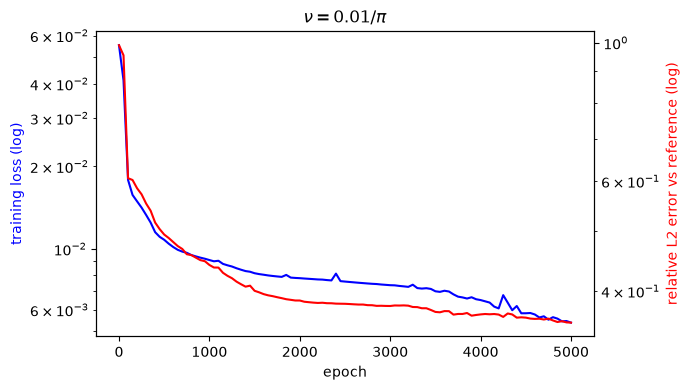

In [16]:
nu = 0.001/np.pi
model_b = SimplePINN()
hist_b = train_with_tracking(model_b, nu)
plot_history(hist_b, r"$\nu = 0.01/\pi$")

In [17]:
def rel_l2_grid(model, table):
    x = torch.tensor(table[:, 0:1], dtype=torch.float32)
    t = torch.tensor(table[:, 1:2], dtype=torch.float32)
    with torch.no_grad():
        u = model(x, t).numpy().ravel()
    return np.linalg.norm(u - table[:, 2]) / np.linalg.norm(table[:, 2])

In [19]:
nu = 0.01/np.pi
xs = np.linspace(-1, 1, 256)
ts = np.linspace(0.01, 1, 100)

U = np.stack([burgers_exact(xs, t, nu) for t in ts], axis=1)   # (256, 100)
X, T = np.meshgrid(xs, ts, indexing="ij")
table = np.column_stack([X.ravel(), T.ravel(), U.ravel()])

In [20]:
print(rel_l2_grid(model1, table))

0.06704530702540146
